# A2 · Image segmentation with boundary-guided feature fusion

This experiment compares fixed and boundary-guided fusion for Oxford-IIIT Pet trimap segmentation. Both variants share an ImageNet-pretrained ResNet18 encoder and boundary supervision, with the adaptive gate based on [Bag in PIDNet (Xu et al., CVPR 2023)](https://doi.org/10.1109/CVPR52729.2023.01871).

## 1. Experimental protocol

The full dataset contains 3,310 training, 370 validation and 3,669 test images. Each variant uses seeds 42–44, 12 epochs, batch size 32, AdamW and cosine learning-rate decay. GPU runs use BF16 autocast with FP32 loss.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

repo_url = "https://github.com/dathuynh1108/CO5085-deep-learning.git"
colab_root = Path("/content/CO5085-deep-learning")
if os.getenv("CO5085_REPO_ROOT"):
    repo = Path(os.environ["CO5085_REPO_ROOT"]).expanduser().resolve()
else:
    candidates = (Path.cwd(), *Path.cwd().parents, colab_root)
    repo = next(
        (path for path in candidates if (path / "src/A2/run.py").is_file()), None
    )
    if repo is None and Path("/content").is_dir():
        subprocess.run(
            ["git", "clone", "--depth", "1", repo_url, str(colab_root)], check=True
        )
        repo = colab_root
if repo is None or not (repo / "src/A2/run.py").is_file():
    raise RuntimeError(
        "Set CO5085_REPO_ROOT to the directory containing the CO5085 source."
    )

os.chdir(repo)
sys.path.insert(0, str(repo / "src"))

In [2]:
import csv
import inspect
import json
import time
from copy import deepcopy
from io import BytesIO
from statistics import mean, stdev

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import PIL
import torch
import torchvision
from IPython.display import Image, Markdown, display
from torch.utils.data import Subset

from A2.data import IGNORE, prepare, read_config, sha256
from A2.models import PetSegmenter, segmentation_loss
from A2.run import (
    evaluate,
    freeze,
    load_dataset,
    loader,
    normalize,
    run_paths,
    signature,
    test_run,
)
from common.runtime import (
    atomic_csv,
    atomic_json,
    atomic_torch_save,
    choose_device,
    environment_info,
    json_hash,
    seed_everything,
    state_fingerprint,
    synchronize,
)

In [3]:
protocol = read_config()
config = deepcopy(protocol)
smoke = os.getenv("CO5085_SMOKE") == "1"
if smoke:
    config.update(epochs=1, seeds=[protocol["seeds"][0]])

data_root = Path(os.getenv("CO5085_DATA_ROOT", repo / "data")).expanduser().resolve()
cache = (
    Path(os.getenv("CO5085_A2_CACHE", data_root / "a2_prepared")).expanduser().resolve()
)
default_output = repo / "runs/notebooks" / ("a2-smoke" if smoke else "a2")
output = Path(os.getenv("CO5085_OUTPUT_ROOT", default_output)).expanduser().resolve()
historical_root = (repo / "runs/assignment2").resolve()
if output.is_relative_to(historical_root) or historical_root.is_relative_to(output):
    raise ValueError("Choose a separate output directory for the A2 notebook.")

In [4]:
device = choose_device(os.getenv("CO5085_DEVICE", "auto"))
workers = int(os.getenv("CO5085_WORKERS", "0"))
threads = int(os.getenv("CO5085_THREADS", "2"))
if workers < 0 or threads < 1:
    raise ValueError(
        "The worker count must be nonnegative and the thread count must be positive."
    )
if device.type == "cuda" and not torch.cuda.is_bf16_supported(
    including_emulation=False
):
    raise RuntimeError("Use a GPU with BF16 support or set CO5085_DEVICE=cpu for FP32.")
torch.set_num_threads(threads)
seed_everything(config["split_seed"])
precision = "bfloat16 autocast" if device.type == "cuda" else "float32"
print(
    json.dumps(
        {
            "config": config,
            "device": str(device),
            "precision": precision,
            "workers": workers,
            "smoke": smoke,
            "output": str(output),
        },
        ensure_ascii=False,
        indent=2,
    )
)

{
  "config": {
    "dataset": "Oxford-IIIT Pet",
    "weights": "ResNet18_Weights.IMAGENET1K_V1",
    "variants": [
      "fixed",
      "guided"
    ],
    "seeds": [
      42,
      43,
      44
    ],
    "split_seed": 2026,
    "validation_per_breed": 10,
    "size": 192,
    "batch_size": 32,
    "epochs": 12,
    "encoder_lr": 0.0002,
    "head_lr": 0.001,
    "weight_decay": 0.0001,
    "boundary_weight": 0.25,
    "precision_cuda": "bfloat16",
    "checkpoint_metric": "validation_miou"
  },
  "device": "cuda",
  "precision": "bfloat16 autocast",
  "workers": 4,
  "smoke": false,
  "output": "/workspace/co5085/runs/notebooks/a2"
}


In [5]:
def show_figure(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(figure)

## 2. Data and label exploration

The [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) trimap separates pet, background and an unclassified transition region, used here as an approximate boundary target. Resizing preserves aspect ratio, and padded pixels are ignored.

In [6]:
manifest_path = cache / "manifest.json"
if not manifest_path.is_file():
    if cache.exists():
        raise FileExistsError(
            f"The cache is incomplete. Choose a new CO5085_A2_CACHE path: {cache}"
        )
    prepare(data_root, cache, protocol)
manifest = json.loads(manifest_path.read_text())
source_identity = signature(cache)
if manifest["config_sha256"] != source_identity["config_sha256"]:
    raise ValueError("The cache was prepared with a different data configuration.")

0.0%

0.0%

0.0%

0.0%

0.0%

0.0%

... (24,744 outputs left out)

99.6%

99.8%

100.0%

100.0%

In [7]:
train_full = load_dataset(cache, "train", manifest)
validation_full = load_dataset(cache, "validation", manifest)
for name, split in manifest["splits"].items():
    print(f"{name:<12} {split['size']:>5,} images, {len(split['breed_counts'])} breeds")
print(
    f"Exact cross-split duplicates excluded: {len(manifest['excluded_cross_split_duplicates'])}"
)

train        3,310 images, 37 breeds
validation     370 images, 37 breeds
test         3,669 images, 37 breeds
Exact cross-split duplicates excluded: 0


Training · median original dimensions 500 × 375 px
  Transition-region share Q1 / median / Q3: 8.6% / 10.9% / 13.8%
Validation · median original dimensions 500 × 375 px
  Transition-region share Q1 / median / Q3: 8.6% / 10.7% / 14.0%


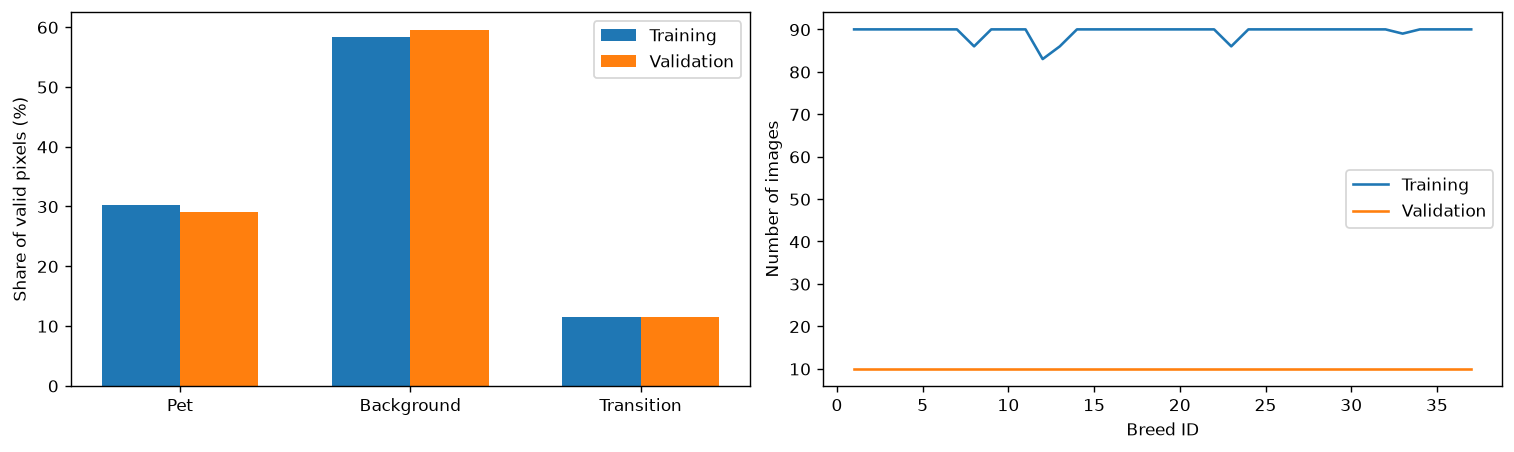

In [8]:
labels = ["Pet", "Background", "Transition"]
partitions = ("train", "validation")
partition_labels = ("Training", "Validation")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for i, (partition, title) in enumerate(zip(partitions, partition_labels, strict=True)):
    split = manifest["splits"][partition]
    eda = split["eda"]
    counts = np.asarray(eda["valid_pixel_counts"])
    shares = 100 * counts / counts.sum()
    axes[0].bar(np.arange(3) + 0.34 * i, shares, width=0.34, label=title)
    q = eda["boundary_share_quartiles"]
    print(
        f"{title} · median original dimensions {eda['width_quartiles'][2]:g} × {eda['height_quartiles'][2]:g} px"
    )
    print(
        f"  Transition-region share Q1 / median / Q3: {q[1]:.1%} / {q[2]:.1%} / {q[3]:.1%}"
    )
    breed_counts = split["breed_counts"]
    axes[1].plot(
        range(1, 38), [breed_counts[str(n)] for n in range(1, 38)], label=title
    )
axes[0].set(
    xticks=np.arange(3) + 0.17, xticklabels=labels, ylabel="Share of valid pixels (%)"
)
axes[1].set(xlabel="Breed ID", ylabel="Number of images")
for axis in axes:
    axis.legend()
show_figure(fig)

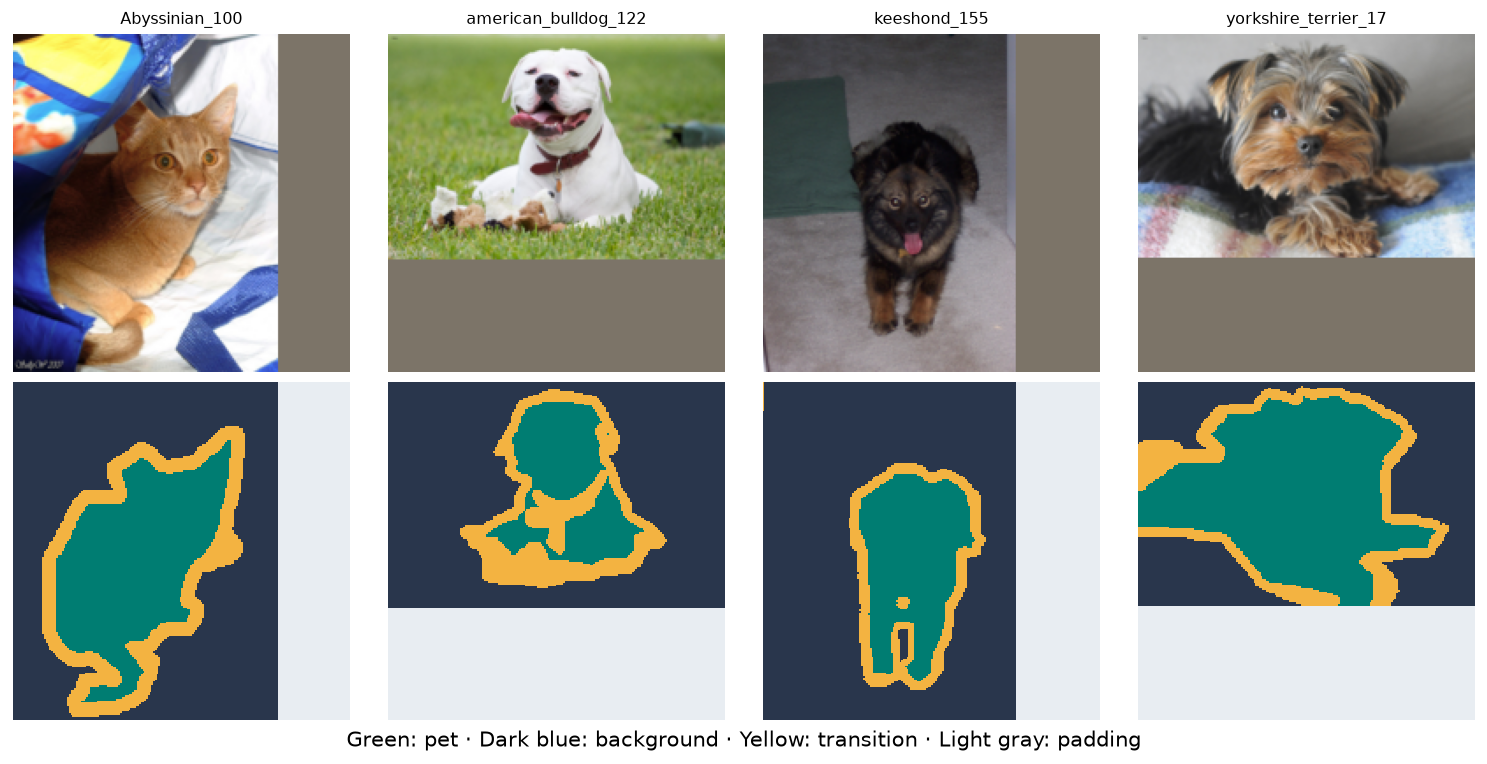

In [9]:
mask_colors = ListedColormap(["#007d72", "#29364c", "#f3b341"])
mask_colors.set_bad("#e8edf2")
fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
for column, index in enumerate(np.linspace(0, len(validation_full) - 1, 4, dtype=int)):
    axes[0, column].imshow(validation_full.images[index])
    axes[0, column].set_title(
        manifest["splits"]["validation"]["names"][index], fontsize=9
    )
    target = np.ma.masked_equal(validation_full.masks[index], IGNORE)
    axes[1, column].imshow(
        target, cmap=mask_colors, vmin=0, vmax=2, interpolation="nearest"
    )
for axis in axes.ravel():
    axis.axis("off")
fig.supxlabel(
    "Green: pet · Dark blue: background · Yellow: transition · Light gray: padding"
)
show_figure(fig)

## 3. Model, training and validation

Fixed fusion averages detail and context features. Guided fusion weights them with the boundary head's sigmoid. Both variants use segmentation cross-entropy and balanced boundary BCE.

This notebook records the current experiment; `src/A2/run.py` provides a separate command-line entry point using the same protocol.

In [10]:
def train_one(variant, seed, path, identity, train_set, val_set):
    path.mkdir(parents=True, exist_ok=False)
    seed_everything(seed)
    model = PetSegmenter(variant, pretrained=True)
    initial_state = state_fingerprint(model.state_dict())
    model.to(device=device, memory_format=torch.channels_last)
    head_params = [
        param
        for name, param in model.named_parameters()
        if not name.startswith("encoder.")
    ]
    optimizer = torch.optim.AdamW(
        [
            {"params": model.encoder.parameters(), "lr": config["encoder_lr"]},
            {"params": head_params, "lr": config["head_lr"]},
        ],
        weight_decay=config["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=config["epochs"]
    )
    train_batches = loader(train_set, config, workers, device, seed, shuffle=True)
    val_batches = loader(val_set, config, workers, device, seed)
    metadata = dict(
        identity,
        config=config,
        variant=variant,
        seed=seed,
        workers=workers,
        initial_state_sha256=initial_state,
        params=sum(p.numel() for p in model.parameters()),
    )
    atomic_json(path / "protocol.json", metadata)

    history = []
    best_score = -1.0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(1, config["epochs"] + 1):
        model.train()
        synchronize(device)
        started = time.perf_counter()
        loss_sum = torch.zeros((), device=device)
        for images, masks in train_batches:
            masks = masks.to(device, non_blocking=True, dtype=torch.long)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"
            ):
                logits, edges = model(normalize(images, device))
            loss = segmentation_loss(logits, edges, masks, config["boundary_weight"])
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach() * len(images)

        synchronize(device)
        seconds = time.perf_counter() - started
        train_loss = float(loss_sum / len(train_set))
        validation, _ = evaluate(model, val_batches, device)
        if not np.isfinite([train_loss, validation["miou"]]).all():
            raise RuntimeError(f"Non-finite metric at {path}, epoch {epoch}.")
        if validation["miou"] > best_score:
            best_score, best_epoch = validation["miou"], epoch
            atomic_torch_save(path / "best.pt", model.state_dict())
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_seconds": seconds,
                "val_miou": validation["miou"],
                "val_macro_dice": validation["macro_dice"],
                "val_transition_iou": validation["iou"][2],
                "encoder_lr": optimizer.param_groups[0]["lr"],
                "head_lr": optimizer.param_groups[1]["lr"],
            }
        )
        atomic_csv(path / "history.csv", history)
        print(
            f"{variant:6} seed={seed} epoch={epoch:02d} loss={train_loss:.4f} "
            f"val_mIoU={validation['miou']:.4f} train={seconds:.1f}s",
            flush=True,
        )
        scheduler.step()
    atomic_json(
        path / "run.json",
        dict(
            metadata,
            epochs=len(history),
            best_epoch=best_epoch,
            best_val_miou=best_score,
            total_train_seconds=sum(row["train_seconds"] for row in history),
            peak_allocated_mib=(
                torch.cuda.max_memory_allocated(device) / 2**20
                if device.type == "cuda"
                else None
            ),
            checkpoint_sha256=sha256(path / "best.pt"),
            history_sha256=sha256(path / "history.csv"),
        ),
    )

In [11]:
def selected_indices(partition):
    total = manifest["splits"][partition]["size"]
    if not smoke:
        return range(total)
    limits = {"train": 32, "validation": 16, "test": 16}
    rng = np.random.default_rng(config["split_seed"])
    return np.sort(
        rng.choice(total, size=min(limits[partition], total), replace=False)
    ).tolist()


def subset_for_run(dataset, partition):
    return Subset(dataset, selected_indices(partition)) if smoke else dataset

In [12]:
identity = dict(
    source_identity,
    notebook_config_sha256=json_hash(config),
    smoke=smoke,
    train_loop_sha256=json_hash({"source": inspect.getsource(train_one)}),
    sample_indices_sha256=json_hash(
        {part: list(selected_indices(part)) for part in manifest["splits"]}
    ),
    runtime=environment_info(device)
    | {
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "pillow": PIL.__version__,
        "precision": precision,
        "workers": workers,
    },
)

In [13]:
train_set = subset_for_run(train_full, "train")
val_set = subset_for_run(validation_full, "validation")
lock_path = output / "frozen.json"
for variant, seed, run_path in run_paths(output, config):
    if (run_path / "run.json").is_file():
        record = json.loads((run_path / "run.json").read_text())
        if (
            any(record.get(key) != value for key, value in identity.items())
            or (record["variant"], record["seed"], record["epochs"])
            != (variant, seed, config["epochs"])
            or record["checkpoint_sha256"] != sha256(run_path / "best.pt")
            or record["history_sha256"] != sha256(run_path / "history.csv")
        ):
            raise ValueError(
                f"Run evidence does not match the notebook protocol: {run_path}"
            )
        print(f"Verified completed run: {variant}, seed {seed}")
        continue
    if lock_path.exists() or run_path.exists():
        raise FileExistsError(
            f"An incomplete run or frozen protocol exists: {run_path}. Choose a new CO5085_OUTPUT_ROOT."
        )
    train_one(variant, seed, run_path, identity, train_set, val_set)

0.3%

0.6%

0.8%

1.1%

1.4%

1.7%

... (421 outputs left out)

guided seed=44 epoch=09 loss=0.2312 val_mIoU=0.7744 train=0.7s


guided seed=44 epoch=10 loss=0.2266 val_mIoU=0.7721 train=0.7s


guided seed=44 epoch=11 loss=0.2223 val_mIoU=0.7736 train=0.7s


guided seed=44 epoch=12 loss=0.2206 val_mIoU=0.7730 train=0.7s


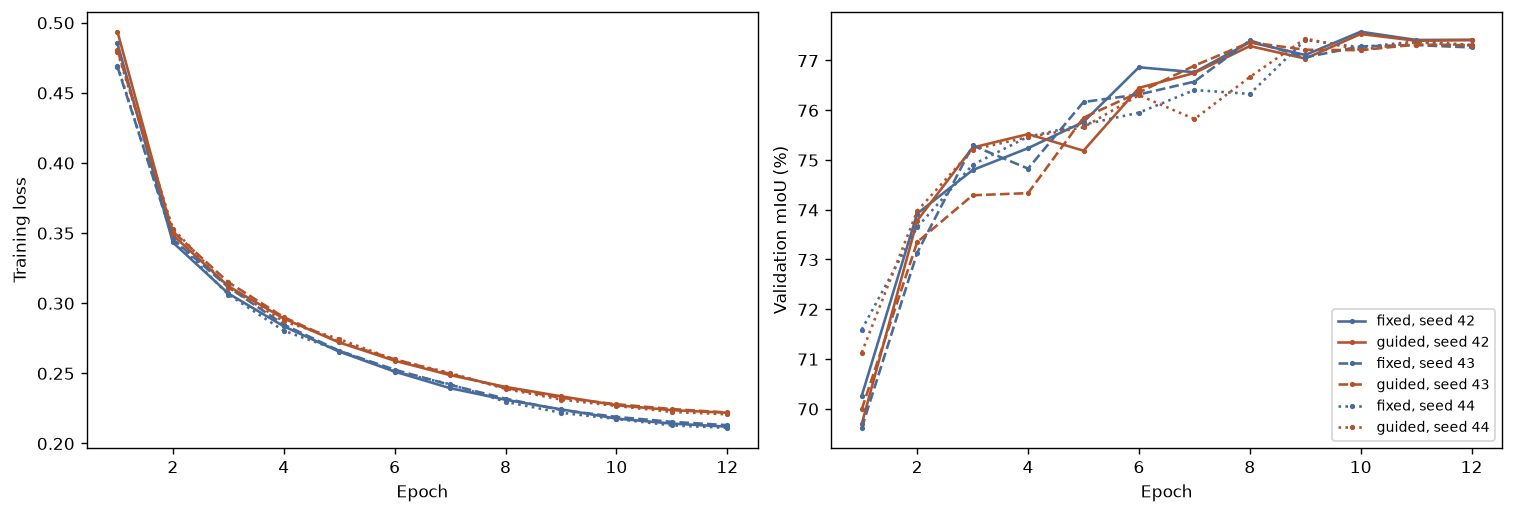

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
variant_colors = {"fixed": "#476b9a", "guided": "#b3532b"}
for variant, seed, run_path in run_paths(output, config):
    with (run_path / "history.csv").open() as stream:
        history = list(csv.DictReader(stream))
    epochs = [int(row["epoch"]) for row in history]
    style = ("-", "--", ":")[config["seeds"].index(seed)]
    line = dict(
        label=f"{variant}, seed {seed}",
        color=variant_colors[variant],
        linestyle=style,
        marker="o",
        markersize=2,
    )
    axes[0].plot(epochs, [float(row["train_loss"]) for row in history], **line)
    axes[1].plot(epochs, [100 * float(row["val_miou"]) for row in history], **line)
axes[0].set(xlabel="Epoch", ylabel="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation mIoU (%)")
axes[1].legend(fontsize=8)
fig.savefig(output / "learning_curves.png", dpi=150)
show_figure(fig)

## 4. Test evaluation

The checkpoint with the highest validation mIoU is selected, retaining the earliest epoch on ties. Test evaluation follows completion of all six runs and a fixed protocol.

In [15]:
frozen = freeze(output, config, identity)
if lock_path.exists():
    if json.loads(lock_path.read_text()) != frozen:
        raise ValueError("The protocol or evidence changed after freezing.")
else:
    atomic_json(lock_path, frozen)
print(f"Frozen {len(frozen['runs'])} runs at {lock_path}.")

Frozen 6 runs at /workspace/co5085/runs/notebooks/a2/frozen.json.


In [16]:
if os.getenv("CO5085_CONFIRM_TEST") != "1":
    if (
        input(
            "Enter TEST to confirm test evaluation after freezing the protocol: "
        ).strip()
        != "TEST"
    ):
        raise RuntimeError("Test evaluation has not been confirmed.")
if json.loads(lock_path.read_text()) != freeze(output, config, identity):
    raise ValueError("The protocol or checkpoint has changed.")

In [17]:
test_full = load_dataset(cache, "test", manifest)
test_set = subset_for_run(test_full, "test")
test_names = [manifest["splits"]["test"]["names"][i] for i in selected_indices("test")]

In [18]:
for variant, seed, run_path in run_paths(output, config):
    result_path = run_path / "test.json"
    if result_path.is_file():
        result = json.loads(result_path.read_text())
        if result["checkpoint_sha256"] != sha256(run_path / "best.pt") or result[
            "per_image_sha256"
        ] != sha256(run_path / "test_per_image.csv"):
            raise ValueError(f"Test evidence has changed: {run_path}")
        print(f"Verified test results: {variant}, seed {seed}")
        continue
    test_run(variant, run_path, test_set, test_names, config, workers, device)

test fixed/seed_42: mIoU=0.7801 Dice=0.8662


test guided/seed_42: mIoU=0.7785 Dice=0.8653


test fixed/seed_43: mIoU=0.7810 Dice=0.8672


test guided/seed_43: mIoU=0.7779 Dice=0.8650


test fixed/seed_44: mIoU=0.7788 Dice=0.8652


test guided/seed_44: mIoU=0.7781 Dice=0.8649


## 5. Metrics, confusion matrices and predictions

In [19]:
results = {}
summary_rows = []
for variant, seed, run_path in run_paths(output, config):
    result = json.loads((run_path / "test.json").read_text())
    results[variant, seed] = result
    summary_rows.append(
        dict(
            variant=variant,
            seed=seed,
            samples=result["samples"],
            miou=result["miou"],
            macro_dice=result["macro_dice"],
            transition_iou=result["iou"][2],
        )
    )
atomic_csv(output / "metrics_by_seed.csv", summary_rows)

In [4]:
metrics = ("miou", "macro_dice", "transition_iou")
per_seed_lines = [
    "| Variant | Seed | mIoU (%) | Macro-Dice (%) | Transition IoU (%) |",
    "|---|---:|---:|---:|---:|",
]
for row in summary_rows:
    values = " | ".join(f"{100 * row[name]:.2f}" for name in metrics)
    per_seed_lines.append(f"| {row['variant']} | {row['seed']} | {values} |")

In [6]:
lines = per_seed_lines.copy()
aggregate = {}
for variant in config["variants"]:
    aggregate[variant] = {}
    for metric in metrics:
        values = [row[metric] for row in summary_rows if row["variant"] == variant]
        aggregate[variant][metric] = dict(
            mean=mean(values), sample_sd=stdev(values) if len(values) > 1 else None
        )
    values = [
        f"{100 * item['mean']:.2f}"
        + (f" ± {100 * item['sample_sd']:.2f}" if item["sample_sd"] is not None else "")
        for item in aggregate[variant].values()
    ]
    lines.append(f"| {variant} | Aggregate | {' | '.join(values)} |")

In [7]:
deltas = {
    seed: results["guided", seed]["miou"] - results["fixed", seed]["miou"]
    for seed in config["seeds"]
}
atomic_json(
    output / "summary.json",
    {"smoke": smoke, "variants": aggregate, "paired_miou_deltas": deltas},
)
display(Markdown("\n".join(lines)))
print(
    "Paired mIoU differences in percentage points:",
    ", ".join(f"seed {seed}: {100 * delta:+.2f}" for seed, delta in deltas.items()),
)

| Variant | Seed | mIoU (%) | Macro-Dice (%) | Transition IoU (%) |
|---|---:|---:|---:|---:|
| fixed | 42 | 78.01 | 86.62 | 55.09 |
| guided | 42 | 77.85 | 86.53 | 55.00 |
| fixed | 43 | 78.10 | 86.72 | 55.57 |
| guided | 43 | 77.79 | 86.50 | 55.15 |
| fixed | 44 | 77.88 | 86.52 | 54.79 |
| guided | 44 | 77.81 | 86.49 | 54.90 |
| fixed | Aggregate | 78.00 ± 0.11 | 86.62 ± 0.10 | 55.15 ± 0.39 |
| guided | Aggregate | 77.82 ± 0.03 | 86.51 ± 0.02 | 55.02 ± 0.13 |

Paired mIoU differences in percentage points: seed 42: -0.16, seed 43: -0.31, seed 44: -0.07


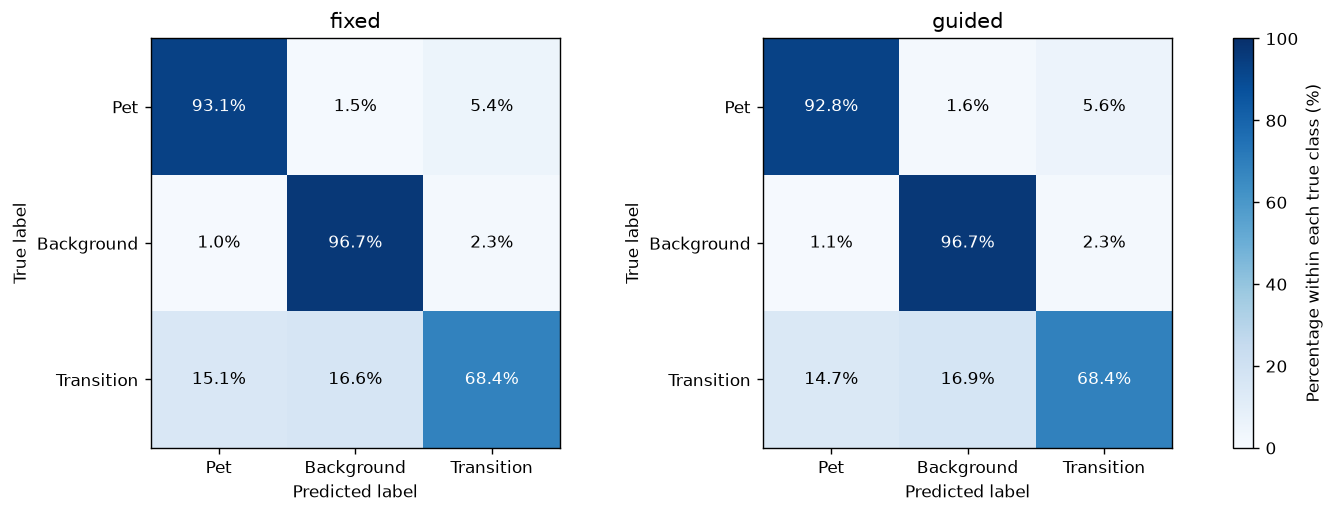

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
confusions = {}
for variant, axis in zip(config["variants"], axes, strict=True):
    counts = np.asarray(
        [results[variant, seed]["confusion"] for seed in config["seeds"]]
    ).sum(axis=0)
    rates = 100 * counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
    confusions[variant] = {"counts": counts.tolist(), "row_percent": rates.tolist()}
    image = axis.imshow(rates, cmap="Blues", vmin=0, vmax=100)
    for (actual, predicted), value in np.ndenumerate(rates):
        axis.text(
            predicted,
            actual,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 50 else "black",
        )
    axis.set(
        title=variant,
        xlabel="Predicted label",
        ylabel="True label",
        xticks=range(3),
        xticklabels=labels,
        yticks=range(3),
        yticklabels=labels,
    )
fig.colorbar(image, ax=axes, label="Percentage within each true class (%)")
atomic_json(output / "pixel_confusion.json", confusions)
fig.savefig(output / "pixel_confusion.png", dpi=150)
show_figure(fig)

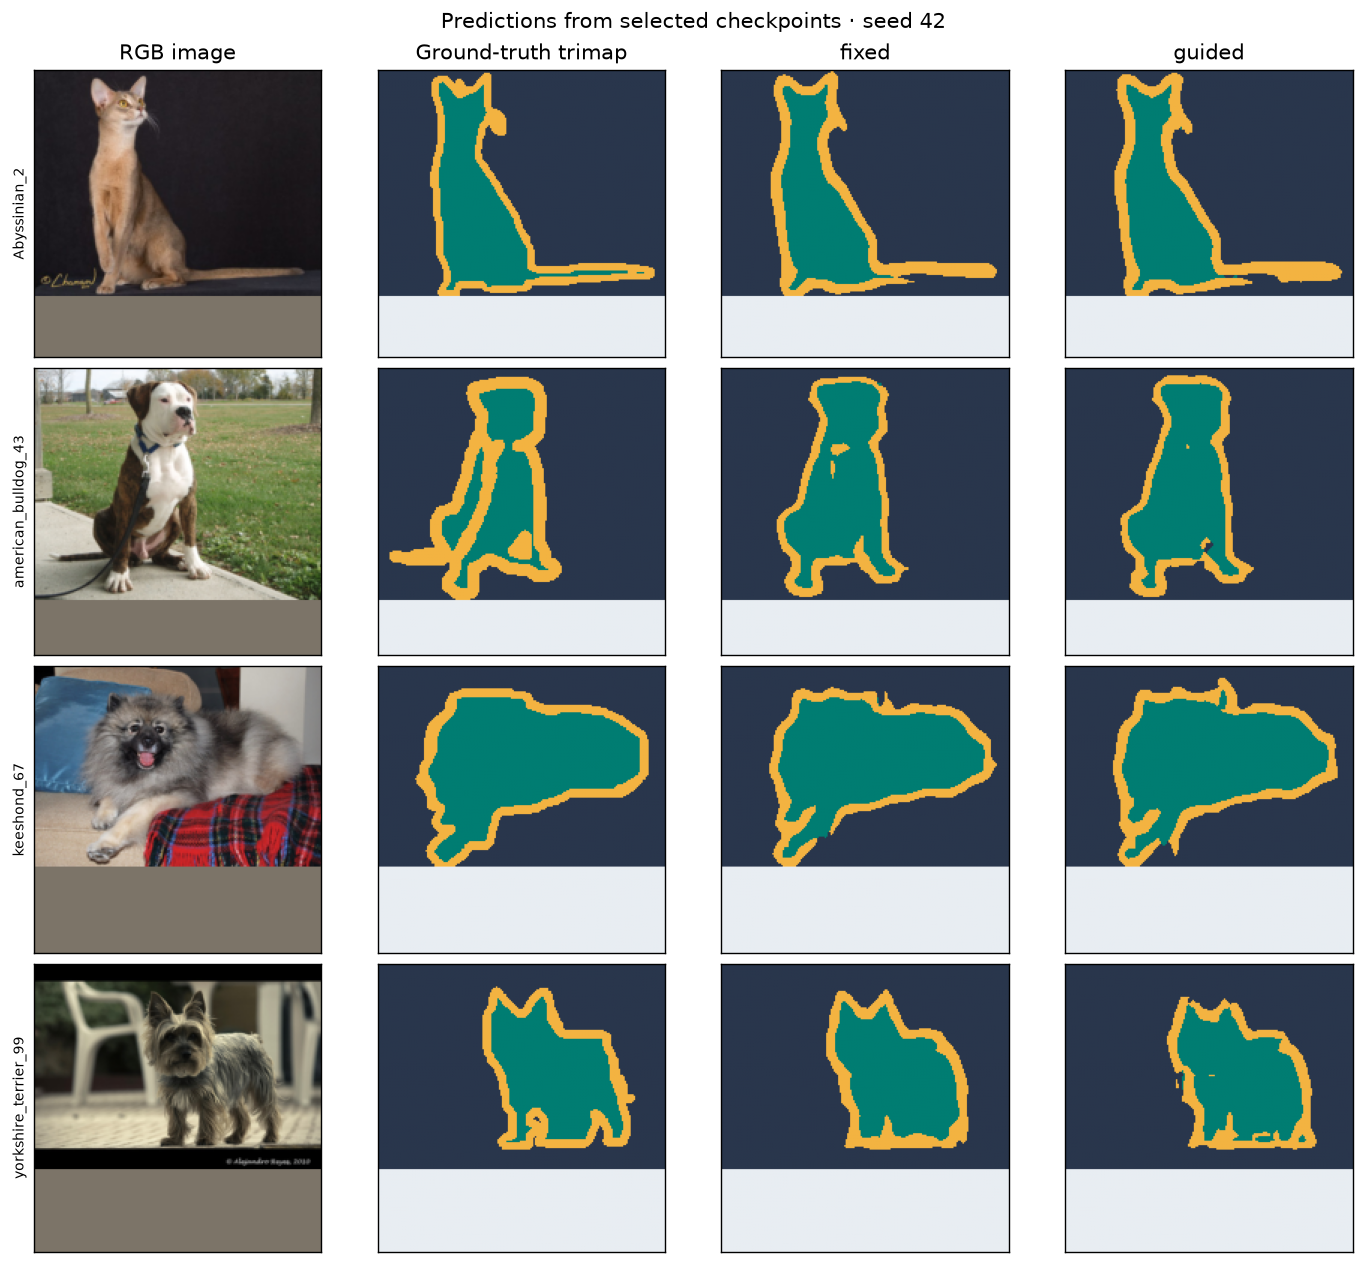

In [24]:
seed = min(config["seeds"])
positions = np.linspace(0, len(test_set) - 1, 4, dtype=int)
examples = [test_set[index] for index in positions]
images = torch.stack([item[0] for item in examples])
masks = torch.stack([item[1] for item in examples]).numpy()
fig, axes = plt.subplots(len(positions), 4, figsize=(11, 10), constrained_layout=True)
for row, position in enumerate(positions):
    axes[row, 0].imshow(images[row].permute(1, 2, 0))
    axes[row, 0].set_ylabel(test_names[position], fontsize=8)
    axes[row, 1].imshow(
        np.ma.masked_equal(masks[row], IGNORE), cmap=mask_colors, vmin=0, vmax=2
    )

for column, variant in enumerate(config["variants"], start=2):
    checkpoint = output / variant / f"seed_{seed}" / "best.pt"
    model = PetSegmenter(variant).to(device=device, memory_format=torch.channels_last)
    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )
    model.eval()
    with (
        torch.inference_mode(),
        torch.autocast(
            device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"
        ),
    ):
        logits, _ = model(normalize(images, device))
    predictions = logits.argmax(dim=1).cpu().numpy()
    for row, prediction in enumerate(predictions):
        axes[row, column].imshow(
            np.ma.masked_where(masks[row] == IGNORE, prediction),
            cmap=mask_colors,
            vmin=0,
            vmax=2,
        )
    del model, logits
for column, title in enumerate(
    ("RGB image", "Ground-truth trimap", *config["variants"])
):
    axes[0, column].set_title(title)
for axis in axes.ravel():
    axis.set(xticks=[], yticks=[])
fig.suptitle(f"Predictions from selected checkpoints · seed {seed}")
fig.savefig(output / "predictions.png", dpi=150)
show_figure(fig)

## 6. Limits of the comparison

This study examines the Bag fusion rule in a ResNet18 segmenter. Trimap width, image resolution and the pet-image domain limit comparisons with full PIDNet and its published Cityscapes results. The [A2 report](../reports/assignment2/assignment2.pdf) analyzes the original method and ablations.

AI assistance: [AI_USE_REPORT.md](../AI_USE_REPORT.md).